<a href="https://colab.research.google.com/github/ancestor9/Scikit-learn-model-selection-evaluation/blob/main/exercise/Listeria_feature_engineering_predict_decision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
path = "/content/drive/MyDrive/MFDS/practice/synthetic_listeria_weather_3x.xlsx"

In [47]:
import pandas as pd

# Excel 파일의 각 시트를 df와 tf로 읽어들이기
df = pd.read_excel(path, sheet_name='synthetic_listeria_lims_data')
tf = pd.read_excel(path, sheet_name='synthetic_weather_daily_101d')

print("df (LIMS) 행 수:", len(df))
print("tf (Weather) 행 수:", len(tf))

df (LIMS) 행 수: 3000
tf (Weather) 행 수: 756


In [48]:
def summarize_df(df: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame([
        {
            'Column': col,
            'Dtype': df[col].dtype,
            'N_Unique': df[col].nunique(),
            'Null_Count': df[col].isnull().sum(),
            'Null_Ratio(%)': round(df[col].isnull().mean() * 100, 2),
            'Sample_Values': df[col].dropna().unique()[:5].tolist()
        }
        for col in df.columns
    ])

In [49]:
summarize_df(df)

,Column,Dtype,N_Unique,Null_Count,Null_Ratio(%),Sample_Values
0,lims_data_key,object,3000,0,0.00,"[O000728_25012600001_1_3, O002012_26072900002_..."
1,hazard_label,object,1,0,0.00,[리스테리아]
2,judge_result,object,2,0,0.00,"[불검출, 검출]"
3,src_route,object,2,0,0.00,"[overseas, domestic]"
4,data_source,object,1,0,0.00,[식약처]
5,expr_iem_nm,object,4,0,0.00,"[리스테리아 모노사이토제네스, Listeria monocytogenes, 리스테리아..."
6,result_value,object,8,0,0.00,"[음성, 불검출, 음성,음성,음성,음성,음성, 음성, 음성, 음성, 음성, 음성, ..."
7,result_value_num,float64,2,2988,99.60,"[0.0, 2.0]"
8,judge_stdr,object,3,2959,98.63,"[n=5, c=0, m=0/25g, 음성, n=5,c=0,m=0/25g]"
9,judge_stdr_num,float64,0,3000,100.00,[]


In [50]:
# summarize_df(df).to_excel("listeria_dataset_selection.xlsx")

In [51]:
selection_list = pd.read_excel("/content/drive/MyDrive/MFDS/practice/listeria_dataset_selection.xlsx")
selection_list[selection_list['feature 포함여부'] == 1]

,Unnamed: 0,Column,Dtype,feature 포함여부,N_Unique,Null_Count,Null_Ratio(%),Sample_Values
2,2,judge_result,object,1,2,0,0.0,"['불검출', '검출']"
3,3,src_route,object,1,2,0,0.0,"['overseas', 'domestic']"
15,15,train_prdlst_nm_2,object,1,6,0,0.0,"['조리식품', '산양유', '아이스크림류', '수산물가공품', '치즈류']"
16,16,prduct_nm,object,1,20,0,0.0,"['수제 떡갈비 정식', '신선한 산양유 500ml', '초코 퍼지 바', '냉동 ..."
18,18,mnfctur_de,object,1,512,0,0.0,"['2025-01-26', '2026-07-29', '2026-01-25', '20..."
20,20,addr,object,1,769,0,0.0,"['충청북도 음성군 대소면 대풍산단로 88-65', '경상남도 양산시 유산공단7길 ..."
23,23,lat,float64,1,2978,0,0.0,"[36.993626, 35.345078, 35.354473, 35.3285, 36...."
24,24,lon,float64,1,2975,0,0.0,"[127.4584, 129.02031, 129.04005, 129.0041, 127..."


In [52]:
# @title **1. 예측에 필요한 컬럼만 추출하여 데이터셋 구성**
selection_list[selection_list['feature 포함여부'] == 1]['Column'].unique()
df = df[selection_list[selection_list['feature 포함여부'] == 1]['Column'].unique()].copy()
summarize_df(df)

,Column,Dtype,N_Unique,Null_Count,Null_Ratio(%),Sample_Values
0,judge_result,object,2,0,0.0,"[불검출, 검출]"
1,src_route,object,2,0,0.0,"[overseas, domestic]"
2,train_prdlst_nm_2,object,6,0,0.0,"[조리식품, 산양유, 아이스크림류, 수산물가공품, 치즈류]"
3,prduct_nm,object,20,0,0.0,"[수제 떡갈비 정식, 신선한 산양유 500ml, 초코 퍼지 바, 냉동 새우살, 자연..."
4,mnfctur_de,object,512,0,0.0,"[2025-01-26, 2026-07-29, 2026-01-25, 2025-03-1..."
5,addr,object,769,0,0.0,"[충청북도 음성군 대소면 대풍산단로 88-65, 경상남도 양산시 유산공단7길 19-..."
6,lat,float64,2978,0,0.0,"[36.993626, 35.345078, 35.354473, 35.3285, 36...."
7,lon,float64,2975,0,0.0,"[127.4584, 129.02031, 129.04005, 129.0041, 127..."


In [53]:
print(f'prduct_nm(품목명)의 종류 : {len(df["prduct_nm"].unique())}')

prduct_nm(품목명)의 종류 : 20


In [54]:
# @title 2. 국내식품만 포함(수입식품은 제외)
df = df[df['src_route'] == 'domestic']
del df['src_route']

In [55]:
# @title 검출률(불량률)
df['judge_result'].value_counts(normalize=True)

,proportion
judge_result,
불검출,0.95358
검출,0.04642


In [56]:
df['mnfctur_de'].max(), df['mnfctur_de'].min()

('2026-10-13', '2025-01-01')

In [57]:
tf['weather_date'] = pd.to_datetime(tf['weather_date'])
tf['weather_date'].max(), tf['weather_date'].min()

(Timestamp('2026-10-13 00:00:00'), Timestamp('2024-09-18 00:00:00'))

## **데이터 전처리**

### **1. addr(주소) 데이터 전처리**

In [58]:
# @title 1. 'addr' 컬럼의 문자열을 공백 기준으로 분할하여 '시도'와 '시군구'를 추출
# 데이터에 결측치나 비정상적인 주소가 있을 수 있으므로 string 타입으로 변환 후 처리
df['sido'] = df['addr'].astype(str).apply(lambda x: x.split()[0] if len(x.split()) > 0 else '')
df['sigungu'] = df['addr'].astype(str).apply(lambda x: x.split()[1] if len(x.split()) > 1 else '')
df['sido'].unique()

array(['경상남도', '경기도', '전북특별자치도', '전라남도', '충청북도', '강원특별자치도', '충청남도'],
      dtype=object)

In [59]:
df['sido'].value_counts()

,count
sido,
경기도,652
강원특별자치도,417
충청남도,372
충청북도,363
경상남도,341
전북특별자치도,341
전라남도,293


In [60]:
df.groupby(['train_prdlst_nm_2', 'sido', 'sigungu']).count()

judge_result  prduct_nm  mnfctur_de  addr  \
train_prdlst_nm_2 sido    sigungu                                              
산양유               강원특별자치도 횡성군                64         64          64    64   
                  경기도     안성시                46         46          46    46   
                          이천시                53         53          53    53   
                  경상남도    양산시                43         43          43    43   
                  전라남도    여수시                47         47          47    47   
                  전북특별자치도 익산시                73         73          73    73   
                  충청남도    천안시                80         80          80    80   
                  충청북도    음성군                58         58          58    58   
수산물가공품            강원특별자치도 횡성군                66         66          66    66   
                  경기도     안성시                71         71          71    71   
                          이천시                55         55          55    55   
                  경상남도    양산시                85         85          85    85   
                  전라남도    여수시                45         45          45    45   
                  전북특별자치도 익산시                62         62          62    62   
                  충청남도    천안시                37         37          37    37   
                  충청북도    음성군                54         54          54    54   
아이스크림류            강원특별자치도 횡성군                44         44          44    44   
                  경기도     안성시                87         87          87    87   
                          이천시                63         63          63    63   
                  경상남도    양산시                53         53          53    53   
                  전라남도    여수시                63         63          63    63   
                  전북특별자치도 익산시                38         38          38    38   
                  충청남도    천안시                55         55          55    55   
                  충청북도    음성군                64         64          64    64   
조리식품              강원특별자치도 횡성군               102        102         102   102   
                  경기도     안성시                38         38          38    38   
                          이천시                52         52          52    52   
                  경상남도    양산시                59         59          59    59   
                  전라남도    여수시                22         22          22    22   
                  전북특별자치도 익산시                78         78          78    78   
                  충청남도    천안시                59         59          59    59   
                  충청북도    음성군                69         69          69    69   
즉석섭취.편의식품류        강원특별자치도 횡성군                73         73          73    73   
                  경기도     안성시                61         61          61    61   
                          이천시                39         39          39    39   
                  경상남도    양산시                43         43          43    43   
                  전라남도    여수시                67         67          67    67   
                  전북특별자치도 익산시                48         48          48    48   
                  충청남도    천안시                49         49          49    49   
                  충청북도    음성군                53         53          53    53   
치즈류               강원특별자치도 횡성군                68         68          68    68   
                  경기도     안성시                34         34          34    34   
                          이천시                53         53          53    53   
                  경상남도    양산시                58         58          58    58   
                  전라남도    여수시                49         49          49    49   
                  전북특별자치도 익산시                42         42          42    42   
                  충청남도    천안시                92         92          92    92   
                  충청북도    음성군                65         65          65    65   

                                  

In [61]:
summarize_df(df)

,Column,Dtype,N_Unique,Null_Count,Null_Ratio(%),Sample_Values
0,judge_result,object,2,0,0.0,"[불검출, 검출]"
1,train_prdlst_nm_2,object,6,0,0.0,"[산양유, 조리식품, 아이스크림류, 수산물가공품, 치즈류]"
2,prduct_nm,object,20,0,0.0,"[신선한 산양유 500ml, 수제 떡갈비 정식, 초코 퍼지 바, 냉동 새우살, 자연..."
3,mnfctur_de,object,492,0,0.0,"[2026-07-29, 2026-01-25, 2025-03-13, 2025-03-1..."
4,addr,object,766,0,0.0,"[경상남도 양산시 유산공단7길 19-14, 경상남도 양산시 유산공단7길 19-74,..."
5,lat,float64,2760,0,0.0,"[35.345078, 35.354473, 35.3285, 36.960964, 35...."
6,lon,float64,2759,0,0.0,"[129.02031, 129.04005, 129.0041, 127.227005, 1..."
7,sido,object,7,0,0.0,"[경상남도, 경기도, 전북특별자치도, 전라남도, 충청북도]"
8,sigungu,object,8,0,0.0,"[양산시, 안성시, 익산시, 이천시, 여수시]"


### **3. 품목군별 Target Mean 적용**
- 데이터가 충분히 많기 떄문에 과거 부적합 비율을 사용해도 무방하다고 판단(Data Leakage는 없다고 판단)

In [62]:
# 원본 데이터 로드 시점의 'judge_result'를 안전하게 다시 가져오거나,
# 기존 값이 문자열인 경우에만 매핑을 적용하고 이미 숫자(0, 1)인 경우는 그대로 유지하도록 합니다.
import pandas as pd

# 안전한 변환을 위한 함수 정의
def safe_map_judge(val):
    if val == '불검출' or val == 0:
        return 0
    elif val == '검출' or val == 1:
        return 1
    return val

df['judge_result'] = df['judge_result'].apply(safe_map_judge)

print("df 'judge_result' 값 분포:")
print(df['judge_result'].value_counts(dropna=False))

df 'judge_result' 값 분포:
judge_result
0    2650
1     129
Name: count, dtype: int64


In [63]:
# train_prdlst_nm_2 단위로 judge_result의 평균값 계산하여 새로운 컬럼으로 추가
target_means = df.groupby('prduct_nm')['judge_result'].mean()
df['prduct_nm_tm'] = df['prduct_nm'].map(target_means)

### **3. 대한 민국을 pixel로 만들어 지역정보를 구분(위도 경도 정보 --> 격자 Grid)**
- 대한민국 정도의 좁은 지역에서는 위도·경도를 다음처럼 근사

> 위도 1° ≈ 111 km

> 경도 1° ≈ 88~92 km 정도

- **make_grid() 함수로 km 단위로 격자 셀을 생성하여 시계열정보와 연계하여 예측 가능**

> **10km, 30km, 50km 등등 Hyperparameter Tunning 실행**

> **기후정보와 join시 위도와 경도가 같은 grid 이면 Join하여 사용**


In [64]:
import geopandas as gpd

def make_grid(df, km, lon_col='lon', lat_col='lat'):
    gdf = gpd.GeoDataFrame(
        df.copy(),
        geometry=gpd.points_from_xy(df[lon_col], df[lat_col]),
        crs='EPSG:4326'
    ).to_crs('EPSG:5179')

    size = km * 1000
    gdf['grid_x'] = (gdf.geometry.x // size).astype(int)
    gdf['grid_y'] = (gdf.geometry.y // size).astype(int)
    gdf['Grid_ID'] = gdf['grid_x'].astype(str) + '_' + gdf['grid_y'].astype(str)

    return gdf

In [65]:
# @title 10 km × 10 km 크기의 격자 중에서 97번째 × 188번째 위치
df = make_grid(df, 10)                                   # 소문자 lon, lat
summarize_df(df)

,Column,Dtype,N_Unique,Null_Count,Null_Ratio(%),Sample_Values
0,judge_result,int64,2,0,0.0,"[0, 1]"
1,train_prdlst_nm_2,object,6,0,0.0,"[산양유, 조리식품, 아이스크림류, 수산물가공품, 치즈류]"
2,prduct_nm,object,20,0,0.0,"[신선한 산양유 500ml, 수제 떡갈비 정식, 초코 퍼지 바, 냉동 새우살, 자연..."
3,mnfctur_de,object,492,0,0.0,"[2026-07-29, 2026-01-25, 2025-03-13, 2025-03-1..."
4,addr,object,766,0,0.0,"[경상남도 양산시 유산공단7길 19-14, 경상남도 양산시 유산공단7길 19-74,..."
5,lat,float64,2760,0,0.0,"[35.345078, 35.354473, 35.3285, 36.960964, 35...."
6,lon,float64,2759,0,0.0,"[129.02031, 129.04005, 129.0041, 127.227005, 1..."
7,sido,object,7,0,0.0,"[경상남도, 경기도, 전북특별자치도, 전라남도, 충청북도]"
8,sigungu,object,8,0,0.0,"[양산시, 안성시, 익산시, 이천시, 여수시]"
9,prduct_nm_tm,float64,19,0,0.0,"[0.10619469026548672, 0.029940119760479042, 0...."


In [66]:
df.drop(columns=['train_prdlst_nm_2', 'addr', 'Grid_ID', 'lat', 'lon', 'geometry'], inplace=True)

### **4. 제품명에 대한 text mining으로 feature 생성**
- LLM에게 제품명에 대해 부적합비율과 관련성이 높은 text를 clustering prompt

In [67]:
summarize_df(df)

,Column,Dtype,N_Unique,Null_Count,Null_Ratio(%),Sample_Values
0,judge_result,int64,2,0,0.0,"[0, 1]"
1,prduct_nm,object,20,0,0.0,"[신선한 산양유 500ml, 수제 떡갈비 정식, 초코 퍼지 바, 냉동 새우살, 자연..."
2,mnfctur_de,object,492,0,0.0,"[2026-07-29, 2026-01-25, 2025-03-13, 2025-03-1..."
3,sido,object,7,0,0.0,"[경상남도, 경기도, 전북특별자치도, 전라남도, 충청북도]"
4,sigungu,object,8,0,0.0,"[양산시, 안성시, 익산시, 이천시, 여수시]"
5,prduct_nm_tm,float64,19,0,0.0,"[0.10619469026548672, 0.029940119760479042, 0...."
6,grid_x,int64,11,0,0.0,"[113, 97, 96, 99, 98]"
7,grid_y,int64,9,0,0.0,"[170, 188, 177, 191, 163]"


In [68]:
df['prduct_nm'].unique()

array(['신선한 산양유 500ml', '수제 떡갈비 정식', '초코 퍼지 바', '냉동 새우살', '자연숙성 체다치즈',
       '까망베르 치즈', '모짜렐라 스트링치즈', '훈제오리 구이', '불고기 도시락', '바닐라 빈 아이스크림',
       '손질 연어 필렛', '렌위치 NY 샌드위치', '유기농 저온살균 우유', '망고 셔벗', '숲속산양목장 산양유',
       '훈제연어 샐러드', '삼치(국내산_해동,전처리,세척전)', '모듬 해물파전', '참치마요 삼각김밥',
       '치킨랩 샌드위치'], dtype=object)

In [69]:
import re

# (공정 분류, 키워드 정규식) - 위에서부터 우선 적용
LISTERIA_RULES = [
    ('훈제(비가열/냉훈 포함)',   r'훈제'),
    ('냉동 디저트',              r'아이스크림|셔벗|퍼지\s*바|아이스바|빙과'),
    ('숙성·연질 치즈',           r'체다|까망베르|브리|숙성.*치즈|블루치즈'),
    ('프레시·가공 치즈',         r'치즈'),
    ('액상 유제품(살균)',        r'우유|산양유|저온살균|요거트|요구르트'),
    ('수산 원료(가열조리 전)',   r'연어|삼치|새우|참치(?!마요)|고등어|오징어|굴|조개|해동|전처리'),
    ('조리 후 냉장·즉석섭취(RTE)', r'도시락|샌드위치|샌드위|삼각김밥|샐러드|김밥|정식|떡갈비|파전|랩'),
]

def classify_listeria_process(name: str) -> str:
    if not isinstance(name, str):
        return '미분류'
    for label, pattern in LISTERIA_RULES:
        if re.search(pattern, name):
            return label
    return '기타'

In [70]:
df['listeria_process'] = df['prduct_nm'].apply(classify_listeria_process)
df['listeria_process'].value_counts()

,count
listeria_process,
조리 후 냉장·즉석섭취(RTE),665
수산 원료(가열조리 전),475
냉동 디저트,467
액상 유제품(살균),464
숙성·연질 치즈,290
훈제(비가열/냉훈 포함),247
프레시·가공 치즈,171


### **5. prduct_nm의 전체 텍스트에 대해 Char/Word N-gram 기반 TF-IDF Vectorizer를 적용**
- TF-IDF + 머신러닝/딥러닝 연계: TF-IDF Vectorizer를 적용한 후 LightGBM, XGBoost 또는 TabNet 모델에 함께 입력값으로 넣어주면 텍스트의 정교한 패턴까지 학습에 활용

In [71]:
summarize_df(df)

,Column,Dtype,N_Unique,Null_Count,Null_Ratio(%),Sample_Values
0,judge_result,int64,2,0,0.0,"[0, 1]"
1,prduct_nm,object,20,0,0.0,"[신선한 산양유 500ml, 수제 떡갈비 정식, 초코 퍼지 바, 냉동 새우살, 자연..."
2,mnfctur_de,object,492,0,0.0,"[2026-07-29, 2026-01-25, 2025-03-13, 2025-03-1..."
3,sido,object,7,0,0.0,"[경상남도, 경기도, 전북특별자치도, 전라남도, 충청북도]"
4,sigungu,object,8,0,0.0,"[양산시, 안성시, 익산시, 이천시, 여수시]"
5,prduct_nm_tm,float64,19,0,0.0,"[0.10619469026548672, 0.029940119760479042, 0...."
6,grid_x,int64,11,0,0.0,"[113, 97, 96, 99, 98]"
7,grid_y,int64,9,0,0.0,"[170, 188, 177, 191, 163]"
8,listeria_process,object,7,0,0.0,"[액상 유제품(살균), 조리 후 냉장·즉석섭취(RTE), 냉동 디저트, 수산 원료(..."


In [73]:
# @title 데이터전처리 후 알고리즘과 pipe 만들기

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

# 1) X / y 분리 후 split
X = df.drop(columns='judge_result')
y = df['judge_result']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2) 컬럼 구분
num_cols  = ['prduct_nm_tm', 'grid_x', 'grid_y']
cat_cols  = ['prduct_nm', 'sido', 'sigungu', 'listeria_process']
date_cols = ['mnfctur_de']

# 3) 제조일자 -> 연/월/요일 (고유값 492개라 그대로 원-핫 하면 안 됨)
def extract_date_parts(X):
    d = pd.to_datetime(X.iloc[:, 0], errors='coerce')
    return pd.DataFrame({'mfr_year': d.dt.year,
                         'mfr_month': d.dt.month,
                         'mfr_dow': d.dt.dayofweek})

def date_feature_names(transformer, input_features):
    return np.array(['mfr_year', 'mfr_month', 'mfr_dow'])

# 4) 전처리기
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot',  OneHotEncoder(handle_unknown='ignore')),
])

date_pipe = Pipeline([
    ('extract', FunctionTransformer(extract_date_parts, feature_names_out=date_feature_names)),
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),
])

preprocessor = ColumnTransformer([
    ('num',  num_pipe,  num_cols),
    ('cat',  cat_pipe,  cat_cols),
    ('date', date_pipe, date_cols),
])

# 5) 최종 파이프라인 (모델은 쿄체 가능)
pipe = Pipeline([
    ('prep',  preprocessor),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced')),
])

### **6. 전체 모델 평가**

In [41]:
!pip install catboost -q

In [77]:
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

from scipy.sparse import csr_matrix, hstack
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
# Gradient Boosting 계열 모델
import lightgbm as lgb
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    auc,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)

from tqdm import tqdm

### **불균형데이터 특성 반영 전체 모델 평가(휴리스틱 수동 설정)**
- 불균형 가중치 조정: 전체 ratio를 그대로 쓰면 과잉검출(FP)이 수천 건 급증하므로, scale_pos_weight 지수를 완화 조율
- 모델 복잡도 제한: max_depth, num_leaves, min_child_samples, min_samples_leaf 등을 통해 트리 깊이를 제한하여 FP 발생을 억제
- F1-Score 기반 임계값(Threshold) 자동 탐색: 고정 $0.5$ 임계값 대신 Precision-Recall 커브에서 F1-Score가 최대가 되는 최적의 임계값을 찾아 분류 기준으로 적용할 수있음

In [ ]:
ratio = (len(y_train) - sum(y_train)) / sum(y_train)

models = {
    'LightGBM': lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=7,
        class_weight='balanced',
        random_state=42,
        verbose=-1,
        n_jobs=-1,
    ),
    'XGBoost': XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        scale_pos_weight=ratio,
        random_state=42,
        n_jobs=-1,
        eval_metric='logloss',
    ),
    'CatBoost': CatBoostClassifier(
        iterations=300,
        learning_rate=0.05,
        scale_pos_weight=ratio,
        random_state=42,
        verbose=0,
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=150, class_weight='balanced', random_state=42, n_jobs=-1
    ),
        'Extra Trees': ExtraTreesClassifier(
        n_estimators=150, class_weight='balanced', random_state=42, n_jobs=-1
    ),
    'Logistic Regression': LogisticRegression(
        class_weight='balanced', max_iter=1000, random_state=42
    ),
}

In [79]:
from scipy.stats import randint, uniform, loguniform
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import (precision_recall_curve, auc, confusion_matrix, roc_auc_score,
                             f1_score, recall_score, precision_score)

# 모델별 탐색 공간 (키 앞에 model__ 접두사)
param_space = {
    'LightGBM': {'model__n_estimators': randint(200, 600),
                 'model__learning_rate': loguniform(0.01, 0.2),
                 'model__max_depth': randint(3, 12),
                 'model__num_leaves': randint(15, 80),
                 'model__subsample': uniform(0.6, 0.4),
                 'model__colsample_bytree': uniform(0.6, 0.4)},
    'XGBoost':  {'model__n_estimators': randint(200, 600),
                 'model__learning_rate': loguniform(0.01, 0.2),
                 'model__max_depth': randint(3, 10),
                 'model__subsample': uniform(0.6, 0.4),
                 'model__colsample_bytree': uniform(0.6, 0.4)},
    'CatBoost': {'model__iterations': randint(200, 600),
                 'model__learning_rate': loguniform(0.01, 0.2),
                 'model__depth': randint(4, 10),
                 'model__l2_leaf_reg': uniform(1, 9)},
    'Random Forest': {'model__n_estimators': randint(100, 400),
                      'model__max_depth': [None, 5, 10, 20],
                      'model__min_samples_leaf': randint(1, 10)},
    'Extra Trees':   {'model__n_estimators': randint(100, 400),
                      'model__max_depth': [None, 5, 10, 20],
                      'model__min_samples_leaf': randint(1, 10)},
    'Logistic Regression': {'model__C': loguniform(1e-3, 1e2),
                            'model__penalty': ['l2']},
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results, best_models = [], {}

for name, model in tqdm(models.items()):
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    search = RandomizedSearchCV(
        pipe, param_space[name], n_iter=20, cv=cv,
        scoring='average_precision',   # PR-AUC 기준
        random_state=42, n_jobs=-1, refit=True, error_score='raise',
    )
    search.fit(X_train, y_train)
    best = search.best_estimator_
    best_models[name] = best

    # 테스트셋 평가
    prob = best.predict_proba(X_test)[:, 1]
    pred = best.predict(X_test)
    p, r, _ = precision_recall_curve(y_test, prob)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

    results.append({
        'Model': name,
        'CV PR-AUC': search.best_score_,
        'PR-AUC': auc(r, p),
        '오류건수(FN+FP)': fn + fp,
        '오탐비율(%)': (fn + fp) / len(y_test) * 100,
        '미검출(FN)': fn,
        '과잉검출(FP)': fp,
        'ROC-AUC': roc_auc_score(y_test, prob),
        'F1-Score': f1_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Best Params': {k.replace('model__', ''): v for k, v in search.best_params_.items()},
    })
    print(f'{name} 완료 | CV PR-AUC={search.best_score_:.4f}')

summary = (pd.DataFrame(results)
           .sort_values('PR-AUC', ascending=False)
           .reset_index(drop=True))

display(summary.drop(columns='Best Params').round(4))

LightGBM 완료 | CV PR-AUC=0.8044
XGBoost 완료 | CV PR-AUC=0.7895
CatBoost 완료 | CV PR-AUC=0.8001
Random Forest 완료 | CV PR-AUC=0.7315
Extra Trees 완료 | CV PR-AUC=0.7602
Logistic Regression 완료 | CV PR-AUC=0.1412


,Model,CV PR-AUC,PR-AUC,오류건수(FN+FP),오탐비율(%),미검출(FN),과잉검출(FP),ROC-AUC,F1-Score,Recall,Precision
0,CatBoost,0.8001,1.0000,0,0.0000,0,0,1.0000,1.0000,1.0000,1.0000
1,XGBoost,0.7895,0.9970,2,0.3597,1,1,0.9999,0.9615,0.9615,0.9615
2,LightGBM,0.8044,0.9960,1,0.1799,1,0,0.9998,0.9804,0.9615,1.0000
3,Extra Trees,0.7602,0.9674,10,1.7986,1,9,0.9979,0.8333,0.9615,0.7353
4,Random Forest,0.7315,0.9580,7,1.2590,4,3,0.9977,0.8627,0.8462,0.8800
5,Logistic Regression,0.1412,0.1231,168,30.2158,6,162,0.7443,0.1923,0.7692,0.1099


In [ ]:
# @title **주요 모델 추가**
from sklearn.ensemble import (GradientBoostingClassifier, HistGradientBoostingClassifier,
                              AdaBoostClassifier, BaggingClassifier)
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from imblearn.ensemble import BalancedRandomForestClassifier, EasyEnsembleClassifier

# ── 모델 추가 ──
models.update({
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'HistGradientBoosting': HistGradientBoostingClassifier(class_weight='balanced', random_state=42),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'Bagging': BaggingClassifier(random_state=42, n_jobs=-1),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'SVM (RBF)': SVC(probability=True, class_weight='balanced', random_state=42),
    'KNN': KNeighborsClassifier(n_jobs=-1),
    'MLP': MLPClassifier(max_iter=500, early_stopping=True, random_state=42),
    'Naive Bayes': GaussianNB(),
})

# ── 탐색 공간 추가 ──
param_space.update({
    'Gradient Boosting': {'model__n_estimators': randint(100, 400),
                          'model__learning_rate': loguniform(0.01, 0.2),
                          'model__max_depth': randint(2, 6),
                          'model__subsample': uniform(0.6, 0.4)},
    'HistGradientBoosting': {'model__learning_rate': loguniform(0.01, 0.2),
                             'model__max_iter': randint(100, 500),
                             'model__max_leaf_nodes': randint(15, 63),
                             'model__l2_regularization': loguniform(1e-3, 10)},
    'AdaBoost': {'model__n_estimators': randint(50, 400),
                 'model__learning_rate': loguniform(0.01, 1.0)},
    'Bagging': {'model__n_estimators': randint(20, 200),
                'model__max_samples': uniform(0.5, 0.5)},
    'Decision Tree': {'model__max_depth': randint(3, 15),
                      'model__min_samples_leaf': randint(1, 20)},
    'SVM (RBF)': {'model__C': loguniform(1e-2, 1e2),
                  'model__gamma': loguniform(1e-4, 1e0)},
    'KNN': {'model__n_neighbors': randint(3, 31),
            'model__weights': ['uniform', 'distance']},
    'MLP': {'model__hidden_layer_sizes': [(64,), (128,), (64, 32)],
            'model__alpha': loguniform(1e-5, 1e-1),
            'model__learning_rate_init': loguniform(1e-4, 1e-2)},
    'Naive Bayes': {'model__var_smoothing': loguniform(1e-10, 1e-5)},
})

# GaussianNB, LDA 등은 희소행렬을 받지 못하므로 전처리 출력을 dense로 고정
preprocessor.set_params(sparse_threshold=0)

In [83]:
# @title  **학습 및 검증데이터 예측**
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results, best_models = [], {}

for name, model in tqdm(models.items()):
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    search = RandomizedSearchCV(
        pipe, param_space[name], n_iter=20, cv=cv,
        scoring='average_precision',   # PR-AUC 기준
        random_state=42, n_jobs=-1, refit=True, error_score='raise',
    )
    search.fit(X_train, y_train)
    best = search.best_estimator_
    best_models[name] = best

    # 테스트셋 평가
    prob = best.predict_proba(X_test)[:, 1]
    pred = best.predict(X_test)
    p, r, _ = precision_recall_curve(y_test, prob)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

    results.append({
        'Model': name,
        'CV PR-AUC': search.best_score_,
        'PR-AUC': auc(r, p),
        '오류건수(FN+FP)': fn + fp,
        '오탐비율(%)': (fn + fp) / len(y_test) * 100,
        '미검출(FN)': fn,
        '과잉검출(FP)': fp,
        'ROC-AUC': roc_auc_score(y_test, prob),
        'F1-Score': f1_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Best Params': {k.replace('model__', ''): v for k, v in search.best_params_.items()},
    })
    print(f'{name} 완료 | CV PR-AUC={search.best_score_:.4f}')

summary = (pd.DataFrame(results)
           .sort_values('PR-AUC', ascending=False)
           .reset_index(drop=True))

display(summary.drop(columns='Best Params').round(4))

  6%|▌         | 1/18 [01:36<27:12, 96.01s/it]

LightGBM 완료 | CV PR-AUC=0.8044


 11%|█         | 2/18 [01:58<14:08, 53.02s/it]

XGBoost 완료 | CV PR-AUC=0.7895


 17%|█▋        | 3/18 [02:51<13:14, 52.98s/it]

CatBoost 완료 | CV PR-AUC=0.8001


... (27 outputs left out)

Balanced RF 완료 | CV PR-AUC=0.4572


100%|██████████| 18/18 [20:25<00:00, 68.06s/it] 

EasyEnsemble 완료 | CV PR-AUC=0.1431


,Model,CV PR-AUC,PR-AUC,오류건수(FN+FP),오탐비율(%),미검출(FN),과잉검출(FP),ROC-AUC,F1-Score,Recall,Precision
0,KNN,0.8084,1.0000,5,0.8993,5,0,1.0000,0.8936,0.8077,1.0000
1,CatBoost,0.8001,1.0000,0,0.0000,0,0,1.0000,1.0000,1.0000,1.0000
2,SVM (RBF),0.7777,1.0000,11,1.9784,0,11,1.0000,0.8254,1.0000,0.7027
3,HistGradientBoosting,0.8013,0.9985,1,0.1799,0,1,0.9999,0.9811,1.0000,0.9630
4,XGBoost,0.7895,0.9970,2,0.3597,1,1,0.9999,0.9615,0.9615,0.9615
5,LightGBM,0.8044,0.9960,1,0.1799,1,0,0.9998,0.9804,0.9615,1.0000
6,Extra Trees,0.7678,0.9680,9,1.6187,1,8,0.9980,0.8475,0.9615,0.7576
7,Gradient Boosting,0.7763,0.9652,2,0.3597,2,0,0.9824,0.9600,0.9231,1.0000
8,Random Forest,0.7333,0.9584,5,0.8993,2,3,0.9979,0.9057,0.9231,0.8889
9,Bagging,0.7649,0.9560,2,0.3597,2,0,0.9730,0.9600,0.9231,1.0000


In [90]:
summary.sort_values('CV PR-AUC', ascending=False).round(0)

,Model,CV PR-AUC,PR-AUC,오류건수(FN+FP),오탐비율(%),미검출(FN),과잉검출(FP),ROC-AUC,F1-Score,Recall,Precision,Best Params
0,KNN,1.0,1.0,5,1.0,5,0,1.0,1.0,1.0,1.0,"{'n_neighbors': 26, 'weights': 'distance'}"
5,LightGBM,1.0,1.0,1,0.0,1,0,1.0,1.0,1.0,1.0,"{'colsample_bytree': 0.9768807022739411, 'lear..."
3,HistGradientBoosting,1.0,1.0,1,0.0,0,1,1.0,1.0,1.0,1.0,"{'l2_regularization': 0.026730883107816707, 'l..."
1,CatBoost,1.0,1.0,0,0.0,0,0,1.0,1.0,1.0,1.0,"{'depth': 9, 'iterations': 493, 'l2_leaf_reg':..."
4,XGBoost,1.0,1.0,2,0.0,1,1,1.0,1.0,1.0,1.0,"{'colsample_bytree': 0.6185801650879991, 'lear..."
2,SVM (RBF),1.0,1.0,11,2.0,0,11,1.0,1.0,1.0,1.0,"{'C': 0.31489116479568624, 'gamma': 0.63512210..."
7,Gradient Boosting,1.0,1.0,2,0.0,2,0,1.0,1.0,1.0,1.0,"{'learning_rate': 0.05036810975099665, 'max_de..."
6,Extra Trees,1.0,1.0,9,2.0,1,8,1.0,1.0,1.0,1.0,"{'max_depth': 20, 'min_samples_leaf': 2, 'n_es..."
9,Bagging,1.0,1.0,2,0.0,2,0,1.0,1.0,1.0,1.0,"{'max_samples': 0.9849549260809971, 'n_estimat..."
8,Random Forest,1.0,1.0,5,1.0,2,3,1.0,1.0,1.0,1.0,"{'max_depth': 20, 'min_samples_leaf': 2, 'n_es..."


In [85]:
print(y_train.sum(), y_test.sum())                    # 양성 개수
print(X_train.merge(X_test, how='inner').shape[0])    # train/test 중복 행 수

# prduct_nm_tm 제외하고 다시 돌려서 점수가 어떻게 변하는지 비교

103 26
1157


In [ ]:
print(y_train.sum(), y_test.sum())                    # 양성 개수
print(X_train.merge(X_test, how='inner').shape[0])    # train/test 중복 행 수

# prduct_nm_tm 제외하고 다시 돌려서 점수가 어떻게 변하는지 비교

CV 점수는 "튜닝 과정에서 이 설정이 얼마나 좋았나"이고, 테스트 점수는 "새 데이터에서 실제로 얼마나 잘 맞히나"입니다. 보통 두 값이 비슷해야 정상입니다.

결과가 이상한 점

- CV PR-AUC는 0.78~0.81인데 테스트 PR-AUC는 거의 전부 1.0000(CatBoost는 오류 0건)입니다. 테스트가 CV보다 0.2 가까이 높은 것은 일반적인 일이 아니고, 아래 가능성을 의심해야 합니다.

> 누수 (가장 유력): 앞서 말씀드린 prduct_nm_tm이 전체 데이터(test 포함)로 계산한 제품명별 타깃 평균이라면, test 행의 정답 정보가 피처에 이미 들어 있습니다. 다만 이 경우 CV 점수도 부풀려지는 게 보통이라, 아래 2번과 함께 확인이 필요합니다.

> test와 train의 중복·유사 행: 같은 제품·지역·제조일 조합이 train과 test에 나뉘어 있으면 test가 쉬워집니다. X_test와 X_train의 중복 행 비율을 확인해 보세요.

> test 양성 수가 너무 적음: 양성이 몇 건 안 되면 PR-AUC가 1.0이 쉽게 나오고 변동도 큽니다. y_test.sum()을 확인하세요. 반대로 CV는 fold별 편차가 클 수 있어 search.cv_results_의 std_test_score도 같이 보면 좋습니다.

In [94]:
# @title **Nested CV(Cross Validation)**
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.base import clone

inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)          # 튜닝용
outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)    # 평가용

scoring = {
    'pr_auc': 'average_precision',
    'roc_auc': 'roc_auc',
    'f1': 'f1',
    'recall': 'recall',
    'precision': 'precision'
}

# 평가할 후보 모델 선택 (models 딕셔너리에 있는 이름 중 선택)
target_models = ['CatBoost', 'LightGBM', 'XGBoost', 'Random Forest']

nested_results = []
for name in tqdm(target_models):
    # 원본 models 딕셔너리를 건드리지 않도록 복제 후 내부 스레드 1로 조정
    est = clone(models[name])
    if 'n_jobs' in est.get_params():
        est.set_params(n_jobs=1)
    if name == 'CatBoost':
        est.set_params(thread_count=1)

    pipe = Pipeline([
        ('prep', clone(preprocessor)),
        ('model', est)
    ])

    search = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=param_space[name],
        n_iter=10,
        cv=inner,
        scoring='average_precision',
        random_state=42,
        n_jobs=-1,
        error_score='raise',
    )

    # X, y 전체를 사용해 엄격한 일반화 성능 평가 (총 5-fold × 3-repeat = 15회 평가)
    cv_res = cross_validate(search, X, y, cv=outer, scoring=scoring, n_jobs=1)

    row = {'Model': name}
    for m in scoring:
        s = cv_res[f'test_{m}']
        row[m] = f'{s.mean():.3f} ± {s.std():.3f}'
    nested_results.append(row)
    print(f'{name} Nested CV 완료 | PR-AUC = {row["pr_auc"]}')

display(pd.DataFrame(nested_results))

CatBoost Nested CV 완료 | PR-AUC = 0.893 ± 0.056
LightGBM Nested CV 완료 | PR-AUC = 0.890 ± 0.051
XGBoost Nested CV 완료 | PR-AUC = 0.886 ± 0.050
Random Forest Nested CV 완료 | PR-AUC = 0.721 ± 0.050


,Model,pr_auc,roc_auc,f1,recall,precision
0,CatBoost,0.893 ± 0.056,0.938 ± 0.036,0.891 ± 0.046,0.874 ± 0.071,0.915 ± 0.065
1,LightGBM,0.890 ± 0.051,0.934 ± 0.028,0.881 ± 0.054,0.863 ± 0.070,0.904 ± 0.064
2,XGBoost,0.886 ± 0.050,0.935 ± 0.033,0.870 ± 0.060,0.869 ± 0.068,0.877 ± 0.085
3,Random Forest,0.721 ± 0.050,0.930 ± 0.030,0.669 ± 0.061,0.809 ± 0.059,0.574 ± 0.079


- 15개의 서로 다른 최적 모델이 생기므로 배포용 단일 모델은 별도 재학습 필요
> 바깥 루프 15번마다 조금씩 다른 최적 하이퍼파라미터가 뽑힐 수 있으므로, Nested CV로 1등 알고리즘(예: CatBoost)을 확정한 뒤에는 전체 데이터(X, y)를 대상으로 일반 RandomizedSearchCV를 한 번 더 돌려 최종 배포용 단일 모델(best_estimator_)을 확정

In [98]:
# @title **15회 outer 평가용**
pd.DataFrame(cv_res).sort_values('test_pr_auc', ascending=False).round(3)

,fit_time,score_time,test_pr_auc,test_roc_auc,test_f1,test_recall,test_precision
12,30.475,0.085,0.799,0.954,0.774,0.923,0.667
6,32.541,0.083,0.787,0.929,0.737,0.808,0.677
9,30.580,0.085,0.772,0.966,0.721,0.880,0.611
0,37.065,0.086,0.763,0.925,0.737,0.808,0.677
13,30.384,0.088,0.750,0.920,0.645,0.769,0.556
2,35.118,0.098,0.738,0.956,0.755,0.769,0.741
11,30.566,0.091,0.738,0.915,0.613,0.731,0.528
14,35.252,0.086,0.731,0.978,0.638,0.880,0.500
7,30.426,0.231,0.717,0.937,0.657,0.846,0.537
4,33.874,0.089,0.697,0.907,0.571,0.720,0.474


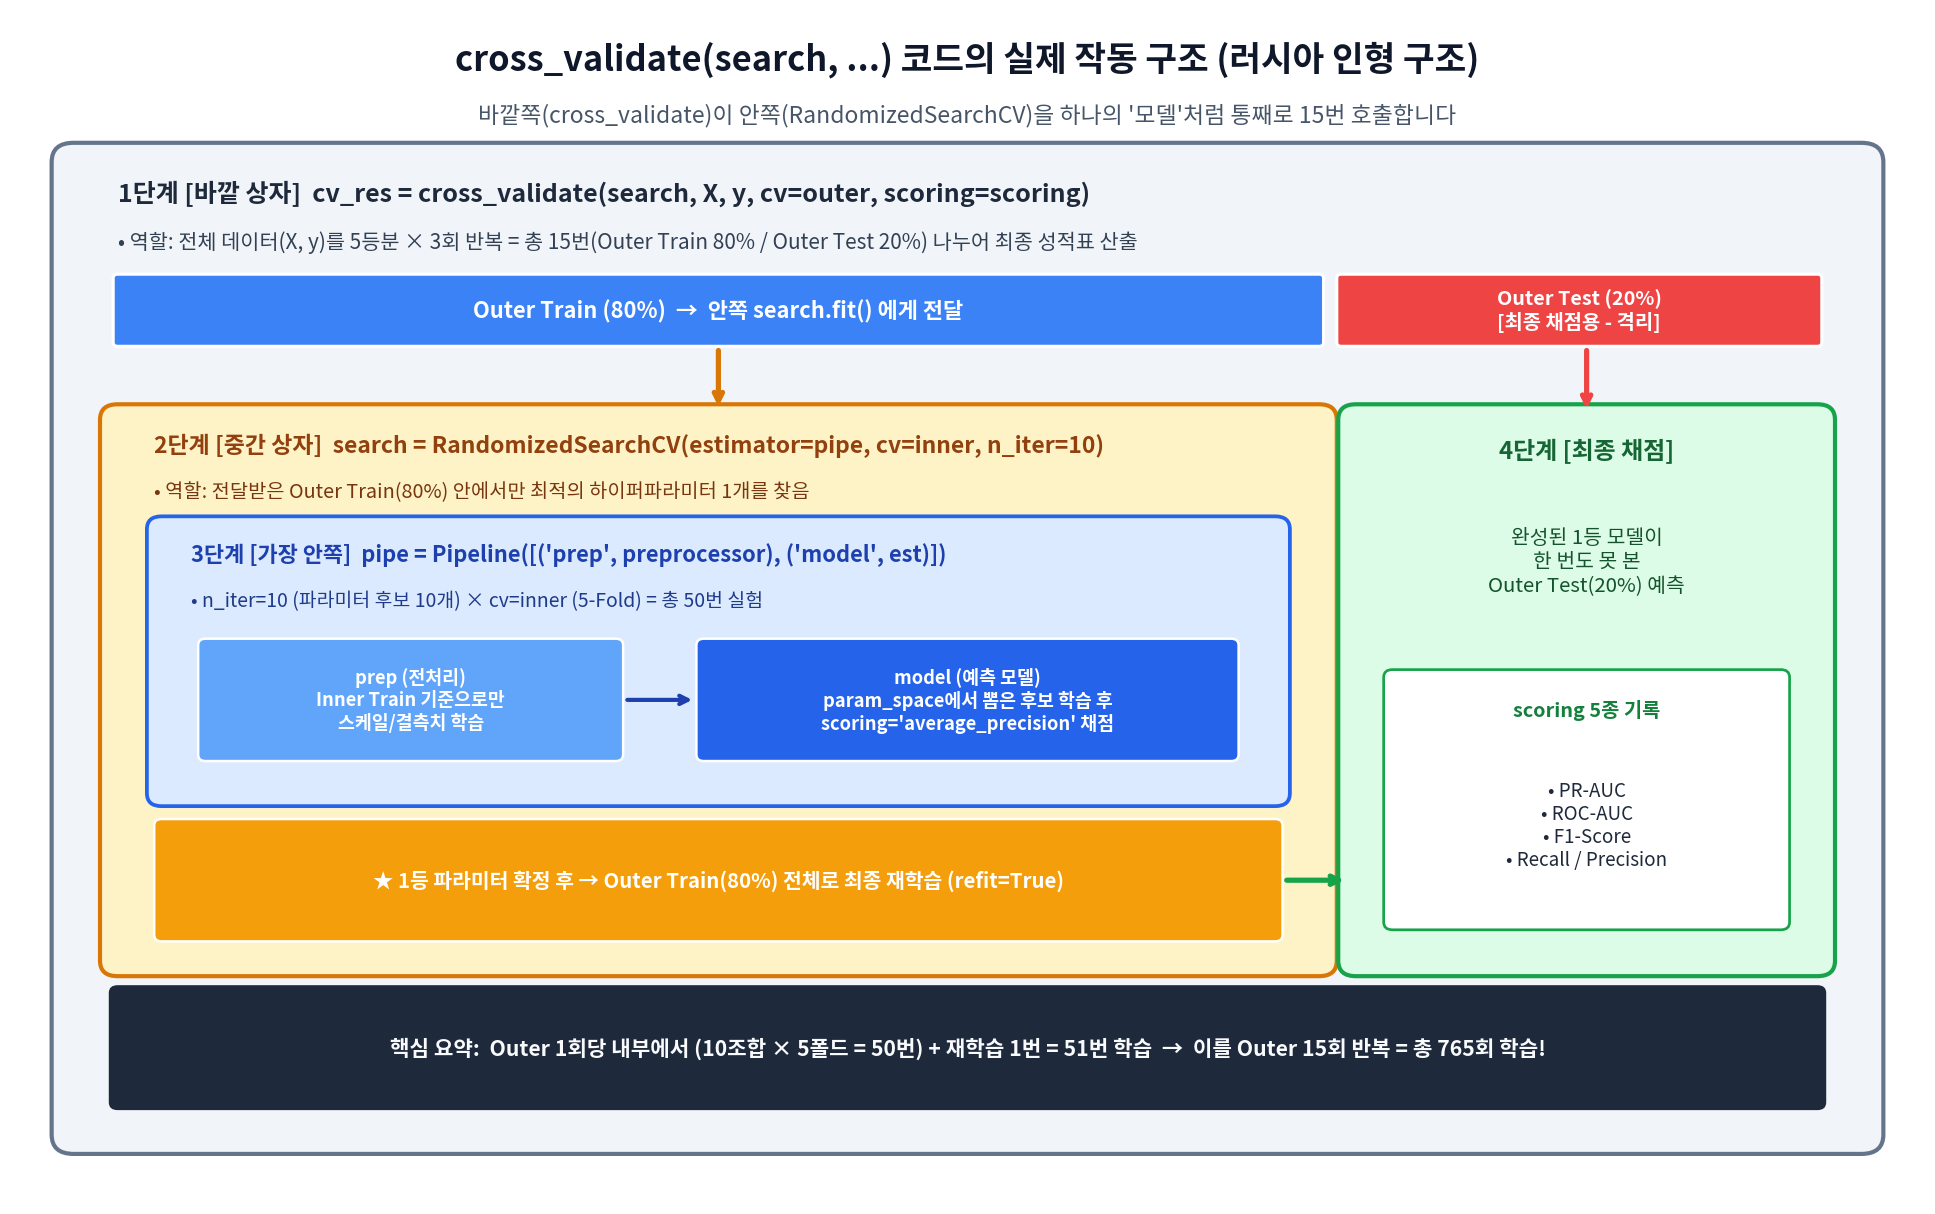

In [99]:
from IPython.display import Image, display
display(Image('/content/drive/MyDrive/MFDS/practice/Code_Generated_Image.png'))

- 실무 활용

> 1단계 (모델 선정): 데이터가 수천 건 이하일 때 Nested CV로 후보 알고리즘(CatBoost, LightGBM 등)들의 거품 없는 진짜 실력(PR-AUC 평균 ± 표준편차)을 비교해 최종 알고리즘 1개를 선정

> 2단계 (최종 모델 확정): 선정된 1등 알고리즘 하나만 가지고 전체 학습 데이터에서 일반 RandomizedSearchCV(refit=True)를 실행해 실제 예측에 쓸 최종 모델 객체를 저장

In [104]:
# @title **Refit**
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.metrics import precision_recall_curve, classification_report, average_precision_score, roc_auc_score

# ==============================================================================
# 1. 최종 CatBoost 파이프라인 구성 (전체 학습 데이터 X_train, y_train 사용)
#    * 별도 홀드아웃 테스트셋이 없다면 X, y 전체를 넣어도 됩니다.
# ==============================================================================
final_catboost = clone(models['CatBoost'])
final_catboost.set_params(thread_count=-1)  # 단일 모델 튜닝이므로 전체 스레드 활용 가능

final_pipe = Pipeline([
    ('prep', clone(preprocessor)),
    ('model', final_catboost)
])

# 1단계에서 CatBoost로 알고리즘을 좁혔으므로 탐색 횟수(n_iter)를 30~50회로 늘려 정밀 탐색
cv_final = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

final_search = RandomizedSearchCV(
    estimator=final_pipe,
    param_distributions=param_space['CatBoost'],
    n_iter=30,
    cv=cv_final,
    scoring='average_precision',  # PR-AUC 기준 최적화
    random_state=42,
    n_jobs=1,                     # CatBoost가 thread_count=-1을 쓰므로 여기는 1로 설정
    refit=True,                   # 1등 파라미터로 X_train 전체 재학습
    error_score='raise'
)

final_search.fit(X_train, y_train)

# 확정된 최종 파이프라인 객체
best_catboost_model = final_search.best_estimator_
best_params = {k.replace('model__', ''): v for k, v in final_search.best_params_.items()}

print(f"최종 CV PR-AUC: {final_search.best_score_:.4f}")
print(f"확정된 최적 파라미터: {best_params}")

# ==============================================================================
# 2. 불균형 데이터용 최적 분류 임계값(Threshold) 산출 (OOF 예측 기반)
# ==============================================================================
oof_probs = cross_val_predict(
    best_catboost_model, X_train, y_train,
    cv=cv_final, method='predict_proba', n_jobs=1
)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_train, oof_probs)
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-12)

best_idx = np.argmax(f1_scores)
best_threshold = float(thresholds[best_idx])

print(f"최적 임계값(Threshold): {best_threshold:.4f} (OOF 최대 F1 = {f1_scores[best_idx]:.4f})")

# ==============================================================================
# 3. 홀드아웃 테스트셋(X_test, y_test)이 있는 경우 최종 검증
# ==============================================================================
test_probs = best_catboost_model.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= best_threshold).astype(int)

print("\n[최종 모델 Test 성능 리포트]")
print(f"Test PR-AUC : {average_precision_score(y_test, test_probs):.4f}")
print(f"Test ROC-AUC: {roc_auc_score(y_test, test_probs):.4f}")
print(classification_report(y_test, test_preds, target_names=['불검출(0)', '검출(1)'], digits=4))

# ==============================================================================
# 4. 운영/배포용 최종 모델 번들 저장 및 추론 예시
# ==============================================================================
model_artifact = {
    'pipeline': best_catboost_model,
    'threshold': best_threshold,
    'best_params': best_params,
    'feature_columns': list(X_train.columns)
}

joblib.dump(model_artifact, 'final_catboost_listeria_model.pkl')
print("저장 완료: final_catboost_listeria_model.pkl")

# --- [참고] 저장된 모델 불러와서 신규 데이터 예측하기 ---
# loaded = joblib.load('final_catboost_listeria_model.pkl')
# new_probs = loaded['pipeline'].predict_proba(X_new)[:, 1]
# new_preds = (new_probs >= loaded['threshold']).astype(int)

최종 CV PR-AUC: 0.8001
확정된 최적 파라미터: {'depth': 9, 'iterations': 493, 'l2_leaf_reg': np.float64(1.007008892569129), 'learning_rate': np.float64(0.19538760104164046)}
최적 임계값(Threshold): 0.9500 (OOF 최대 F1 = 0.8541)

[최종 모델 Test 성능 리포트]
Test PR-AUC : 1.0000
Test ROC-AUC: 1.0000
              precision    recall  f1-score   support

      불검출(0)     0.9962    1.0000    0.9981       530
       검출(1)     1.0000    0.9231    0.9600        26

    accuracy                         0.9964       556
   macro avg     0.9981    0.9615    0.9791       556
weighted avg     0.9964    0.9964    0.9963       556

저장 완료: final_catboost_listeria_model.pkl


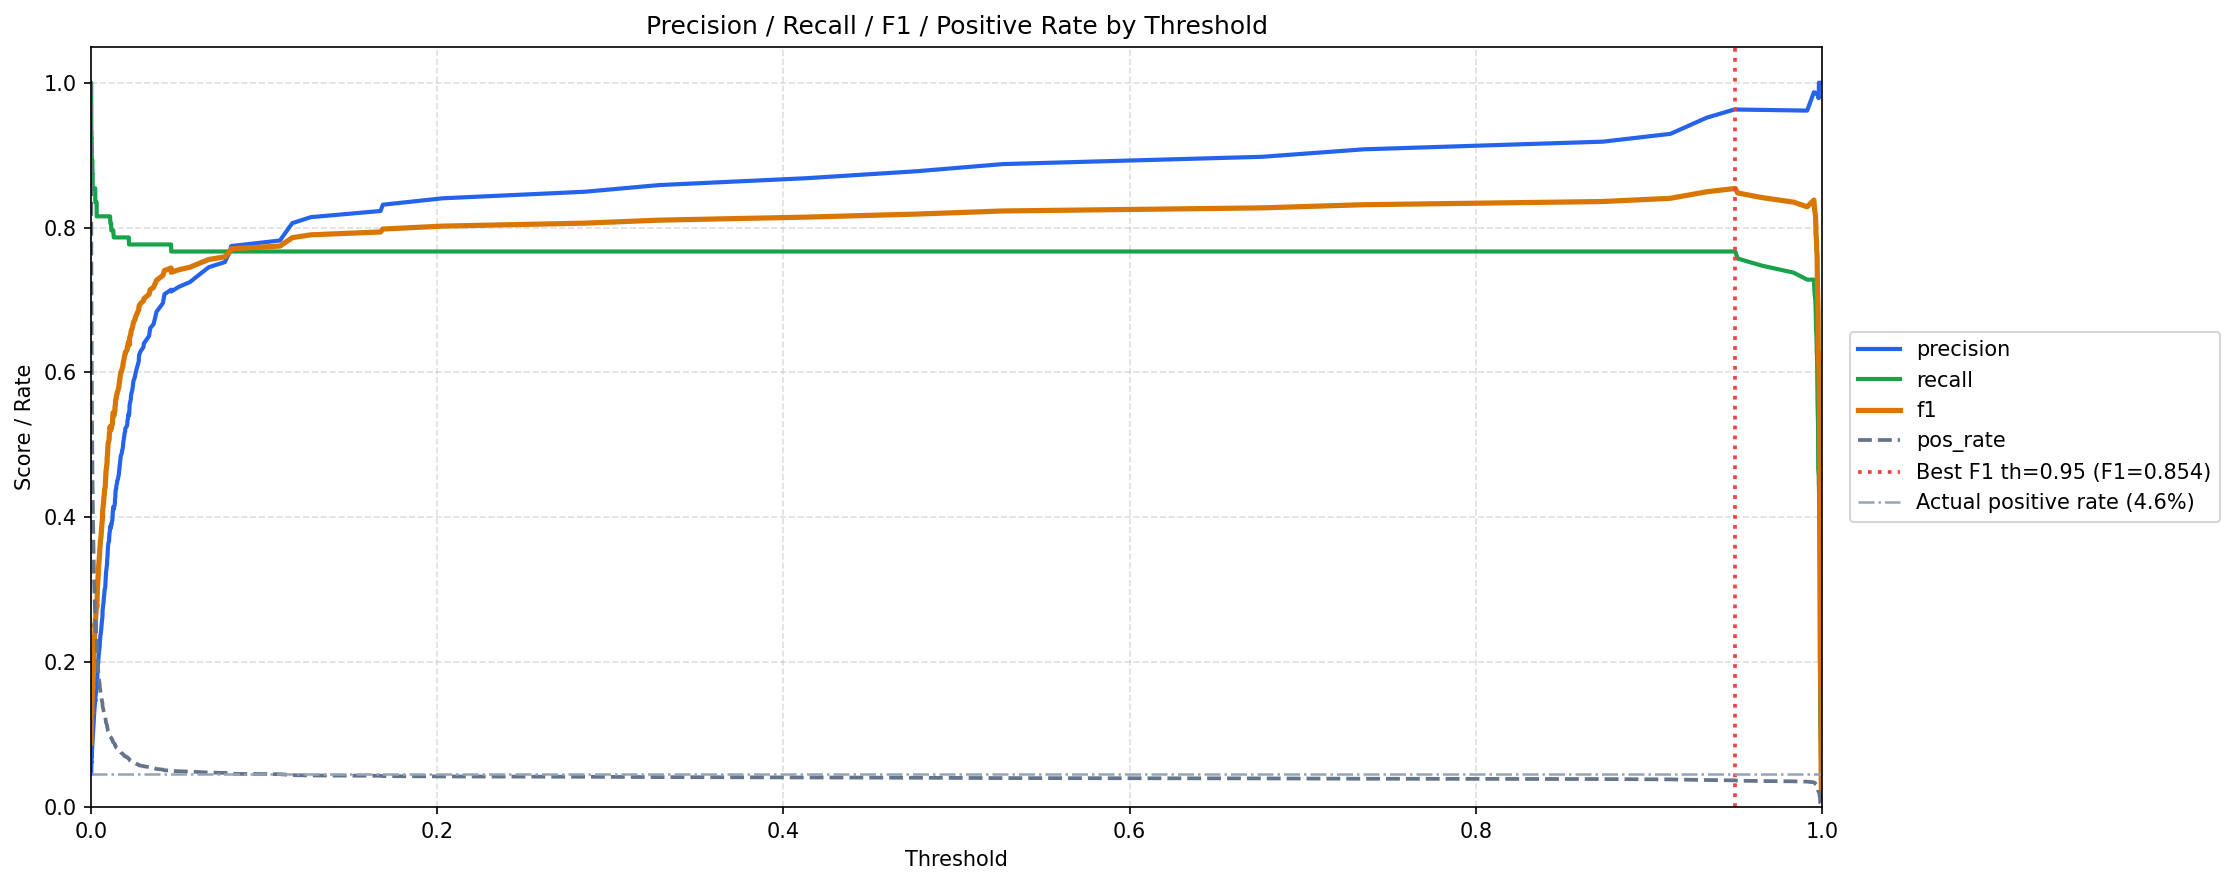

****************************************************************************************************


,threshold,precision,recall,f1,pos_rate
1734,0.91,0.93,0.77,0.84,0.04
1735,0.93,0.95,0.77,0.85,0.04
1736,0.95,0.96,0.77,0.85,0.04
1737,0.95,0.96,0.76,0.85,0.04
1738,0.97,0.96,0.75,0.84,0.04
...,...,...,...,...,...
1798,1.00,1.00,0.05,0.09,0.00
1799,1.00,1.00,0.04,0.07,0.00
1800,1.00,1.00,0.03,0.06,0.00
1801,1.00,1.00,0.02,0.04,0.00


In [105]:
# @title **decision threshhold visualization**
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

y_true, y_prob = np.asarray(y_train), np.asarray(oof_probs)

p, r, th = precision_recall_curve(y_true, y_prob)
df_th = pd.DataFrame({'threshold': th, 'precision': p[:-1], 'recall': r[:-1]})
df_th['f1'] = 2 * df_th.precision * df_th.recall / (df_th.precision + df_th.recall).clip(lower=1e-12)
df_th['pos_rate'] = [(y_prob >= t).mean() for t in df_th.threshold]

best = df_th.loc[df_th.f1.idxmax()]

fig, ax = plt.subplots(figsize=(15, 6), dpi=150)
for col, c, ls, lw in [('precision', '#2563EB', '-', 2), ('recall', '#16A34A', '-', 2),
                       ('f1', '#D97706', '-', 2.5), ('pos_rate', '#64748B', '--', 1.8)]:
    ax.plot(df_th.threshold, df_th[col], color=c, ls=ls, lw=lw, label=col)

ax.axvline(best.threshold, color='#EF4444', ls=':', lw=1.8,
           label=f'Best F1 th={best.threshold:.2f} (F1={best.f1:.3f})')
ax.axhline(y_true.mean(), color='#94A3B8', ls='-.', lw=1.2,
           label=f'Actual positive rate ({y_true.mean():.1%})')

ax.set(title='Precision / Recall / F1 / Positive Rate by Threshold',
       xlabel='Threshold', ylabel='Score / Rate', xlim=(0, 1), ylim=(0, 1.05))
ax.grid(True, ls='--', alpha=0.4)
ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=True)
plt.tight_layout(); plt.show()

print('*'*100)
display(df_th[df_th.threshold.between(best.threshold - 0.05, best.threshold + 0.05)].round(2))